# Retail Demand Forecasting & Replenishment
**EN:** Daily sales forecasting for Favorita stores (Kaggle Store Sales), then an inventory simulation that turns forecasts into orders.
Heavy logic lives in `src/`; this notebook runs the steps and shows the results.

**TR:** Favorita mağazaları için günlük satış tahmini (Kaggle Store Sales), ardından tahminleri siparişe çeviren bir stok simülasyonu.
Asıl kod `src/` klasöründe; bu notebook adımları çalıştırır ve sonuçları gösterir.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import data

pd.set_option("display.width", 120)
data.FIG_DIR.mkdir(parents=True, exist_ok=True)

## Step 1 — Data check / Adım 1 — Veri kontrolü
**EN:** Look at size, date range, missing values, zero sales and the sales trend. Then pick a scope that runs fast on a laptop.

**TR:** Boyut, tarih aralığı, eksik değerler, sıfır satışlar ve satış trendine bakıyoruz. Sonra laptopta hızlı çalışacak bir kapsam seçiyoruz.

In [2]:
# Full training file: size, dates, missing values
# Tüm eğitim dosyası: boyut, tarihler, eksik değerler
train = data.load_train()
print("rows:", len(train), "| stores:", train.store_nbr.nunique(), "| families:", train.family.nunique())
print("dates:", train.date.min().date(), "->", train.date.max().date())

# Missing calendar days (stores closed on Dec 25)
# Takvimde eksik günler (25 Aralık mağazalar kapalı)
full = pd.date_range(train.date.min(), train.date.max())
print("missing days:", [d.date() for d in full.difference(train.date.unique())])
print("missing values per column:", train.isna().sum().to_dict())

rows: 3000888 | stores: 54 | families: 33
dates: 2013-01-01 -> 2017-08-15
missing days: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
missing values per column: {'date': 0, 'store_nbr': 0, 'family': 0, 'sales': 0, 'onpromotion': 0}


In [3]:
# Zero sales: how common, and which families
# Sıfır satışlar: ne kadar yaygın, hangi ailelerde
print("zero-sales share (all):", round((train.sales == 0).mean(), 3))
zero_by_fam = train.groupby("family", observed=True).sales.apply(lambda s: (s == 0).mean())
share_by_fam = train.groupby("family", observed=True).sales.sum() / train.sales.sum()
pd.DataFrame({"sales_share": share_by_fam, "zero_share": zero_by_fam}).sort_values("sales_share", ascending=False).round(3).head(15)

zero-sales share (all): 0.313


,sales_share,zero_share
family,,
GROCERY I,0.320,0.081
BEVERAGES,0.202,0.081
PRODUCE,0.114,0.284
CLEANING,0.091,0.081
DAIRY,0.060,0.081
BREAD/BAKERY,0.039,0.081
POULTRY,0.030,0.081
MEATS,0.029,0.081
PERSONAL CARE,0.023,0.081


In [4]:
# Other files: rows and missing values
# Diğer dosyalar: satır sayısı ve eksik değerler
for name, df in {"oil": pd.read_csv(data.DATA_DIR / "oil.csv"),
                 "holidays": data.load_holidays(),
                 "transactions": data.load_transactions(),
                 "stores": data.load_stores()}.items():
    print(f"{name:13s} rows={len(df):6d} missing={df.isna().sum().sum()}")
print(data.load_holidays().type.value_counts().to_dict())

oil           rows=  1218 missing=43
holidays      rows=   350 missing=0
transactions  rows= 83488 missing=0
stores        rows=    54 missing=0
{'Holiday': 221, 'Event': 56, 'Additional': 51, 'Transfer': 12, 'Bridge': 5, 'Work Day': 5}


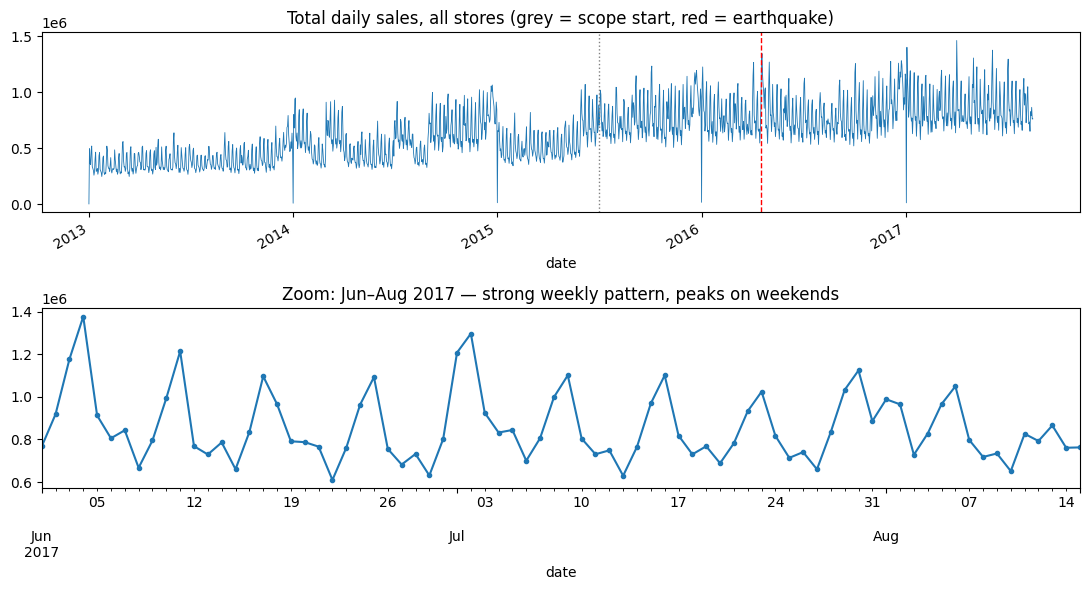

In [5]:
# Total sales over time; red line = 2016-04-16 earthquake
# Zaman içinde toplam satış; kırmızı çizgi = 16.04.2016 depremi
daily = train.groupby("date").sales.sum()
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
daily.plot(ax=ax[0], lw=0.6)
ax[0].axvline(pd.Timestamp("2016-04-16"), color="red", ls="--", lw=1)
ax[0].axvline(pd.Timestamp(data.SCOPE_START), color="grey", ls=":", lw=1)
ax[0].set_title("Total daily sales, all stores (grey = scope start, red = earthquake)")
daily["2017-06-01":].plot(ax=ax[1], marker=".")
ax[1].set_title("Zoom: Jun–Aug 2017 — strong weekly pattern, peaks on weekends")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "01_sales_over_time.png", dpi=110); plt.show()

In [6]:
# Chosen scope: all 54 stores x top-10 families, from 2015-07-01
# Seçilen kapsam: 54 mağaza x ilk 10 aile, 2015-07-01'den itibaren
df = data.load_scope()
n_series = df.groupby(["store_nbr", "family"], observed=True).ngroups
print("rows:", len(df), "| series:", n_series, "| dates:", df.date.min().date(), "->", df.date.max().date())
print("families:", list(df.family.cat.categories))
print("share of total sales covered:", round(df.sales.sum() / train.loc[train.date >= data.SCOPE_START, "sales"].sum(), 3))
print("zero-sales share in scope:", round((df.sales == 0).mean(), 3))

rows: 411250 | series: 540 | dates: 2015-07-01 -> 2017-08-15
families: ['BEVERAGES', 'BREAD/BAKERY', 'CLEANING', 'DAIRY', 'DELI', 'GROCERY I', 'MEATS', 'PERSONAL CARE', 'POULTRY', 'PRODUCE']


share of total sales covered: 0.93
zero-sales share in scope: 0.01
